# Ames Housing: remodeling, home age, and sale prices

**Question:** How does remodeling status relate to home sale prices, and does this relationship differ depending on the age of the home when controlling for square footage and overall quality?

This notebook loads and cleans the needed variables, explores sale prices with tables and charts, and fits a multiple linear regression with a remodeling-by-age interaction. Run the cells in order with `AmesHousing.csv` in the same directory as this notebook. Requires pandas, matplotlib, seaborn, statsmodels, and a Python Jupyter kernel.

## 1. Load the data and display the first five rows

In [1]:
import pandas as pd

df = pd.read_csv('AmesHousing.csv')
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 2. Dataset dimensions and column names

In [2]:
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
print('Column names:')
print(df.columns.tolist())

Rows: 2930
Columns: 82
Column names:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual', 'Gar

## 3. Missing values and duplicate records

Inspect every column, but only clean columns used in the question. Missing values in unrelated columns will not cause a row to be removed. A duplicate record means an exact match across all original columns.

In [3]:
print('Missing values by column:')
print(df.isna().sum().to_string())
print('Total missing values:', df.isna().sum().sum())
print('Exact duplicate records:', df.duplicated().sum())

Missing values by column:
Order                 0
PID                   0
MS SubClass           0
MS Zoning             0
Lot Frontage        490
Lot Area              0
Street                0
Alley              2732
Lot Shape             0
Land Contour          0
Utilities             0
Lot Config            0
Land Slope            0
Neighborhood          0
Condition 1           0
Condition 2           0
Bldg Type             0
House Style           0
Overall Qual          0
Overall Cond          0
Year Built            0
Year Remod/Add        0
Roof Style            0
Roof Matl             0
Exterior 1st          0
Exterior 2nd          0
Mas Vnr Type       1775
Mas Vnr Area         23
Exter Qual            0
Exter Cond            0
Foundation            0
Bsmt Qual            80
Bsmt Cond            80
Bsmt Exposure        83
BsmtFin Type 1       80
BsmtFin SF 1          1
BsmtFin Type 2       81
BsmtFin SF 2          1
Bsmt Unf SF           1
Total Bsmt SF         1
Heating       

## 4. Variables needed for the question

| Variable | Purpose |
| --- | --- |
| `SalePrice` | Home sale price, the outcome |
| `Year Built` | Construction year; needed for home age and remodeling status |
| `Year Remod/Add` | Recorded remodeling/addition year; needed for remodeling status |
| `Yr Sold` | Sale year; needed for age at sale |
| `Gr Liv Area` | Above ground living area in square feet; the square footage control |
| `Overall Qual` | Overall material and finish quality, rated 1–10; the quality control |

We will create `HomeAge = Yr Sold - Year Built` and `Remodeled = 1` when `Year Remod/Add > Year Built`, otherwise `0`. This is an indicator based on the recorded years, not a complete renovation history. It does not identify the type or extent of work. We retain age as a numeric variable so a later analysis can examine whether the remodeling relationship changes with age.

In [4]:
needed_columns = [
    'SalePrice', 'Year Built', 'Year Remod/Add',
    'Yr Sold', 'Gr Liv Area', 'Overall Qual'
]

# Remove only exact duplicates across the original full records.
# Different homes can legitimately share values in these six columns.
analysis_df = df.drop_duplicates()[needed_columns].copy()
print('Rows removed as exact duplicates:', len(df) - len(analysis_df))
print('Original data types:')
print(analysis_df.dtypes)
print('Missing values in needed columns:')
print(analysis_df.isna().sum())

Rows removed as exact duplicates: 0
Original data types:
SalePrice         int64
Year Built        int64
Year Remod/Add    int64
Yr Sold           int64
Gr Liv Area       int64
Overall Qual      int64
dtype: object
Missing values in needed columns:
SalePrice         0
Year Built        0
Year Remod/Add    0
Yr Sold           0
Gr Liv Area       0
Overall Qual      0
dtype: int64


## 5. Clean only the necessary variables

Ensure these six columns are numeric. Any unreadable numeric entry becomes missing. Remove rows missing a required value instead of guessing sale prices, years, area, or quality. The supplied file has no missing values in these columns, so this step should remove no rows.

In [5]:
for column in needed_columns:
    analysis_df[column] = pd.to_numeric(analysis_df[column], errors='coerce')

print('Missing values after numeric conversion:')
print(analysis_df.isna().sum())
rows_before = len(analysis_df)
analysis_df = analysis_df.dropna(subset=needed_columns).copy()
print('Rows removed for missing required values:', rows_before - len(analysis_df))

Missing values after numeric conversion:
SalePrice         0
Year Built        0
Year Remod/Add    0
Yr Sold           0
Gr Liv Area       0
Overall Qual      0
dtype: int64
Rows removed for missing required values: 0


Check that price and living area are positive, quality is an integer from 1 to 10, and years are positive whole numbers in a consistent order: construction year ≤ remodeling year ≤ sale year.

The supplied file contains four records with inconsistent year order. These would make home age or remodeling status unreliable. Display them before excluding them. This is an explicit preparation choice: their intended years are unknown, so we do not guess corrections. Large prices or large homes are not removed simply because they are unusual.

In [6]:
year_columns = ['Year Built', 'Year Remod/Add', 'Yr Sold']

valid_values = (
    (analysis_df['SalePrice'] > 0)
    & (analysis_df['Gr Liv Area'] > 0)
    & analysis_df['Overall Qual'].between(1, 10)
    & (analysis_df['Overall Qual'] % 1 == 0)
    & (analysis_df[year_columns] > 0).all(axis=1)
    & (analysis_df[year_columns] % 1 == 0).all(axis=1)
)

valid_year_order = (
    (analysis_df['Year Built'] <= analysis_df['Year Remod/Add'])
    & (analysis_df['Year Remod/Add'] <= analysis_df['Yr Sold'])
)

valid_rows = valid_values & valid_year_order
print('Records excluded for invalid values or inconsistent years:')
print(analysis_df.loc[~valid_rows].to_string())
print('Rows excluded:', (~valid_rows).sum())
analysis_df = analysis_df.loc[valid_rows].copy()

Records excluded for invalid values or inconsistent years:
      SalePrice  Year Built  Year Remod/Add  Yr Sold  Gr Liv Area  Overall Qual
850      203000        2002            2001     2009         1444             7
1702     260116        2007            2008     2007         2152             8
2180     183850        2008            2009     2007         5095            10
2181     184750        2007            2008     2007         4676            10
Rows excluded: 4


## 6. Prepare home age and remodeling status

In [7]:
analysis_df['HomeAge'] = analysis_df['Yr Sold'] - analysis_df['Year Built']
analysis_df['Remodeled'] = (
    analysis_df['Year Remod/Add'] > analysis_df['Year Built']
).astype(int)

analysis_df = analysis_df.reset_index(drop=True)
print('Cleaned dimensions:', analysis_df.shape)
print('Total rows removed:', len(df) - len(analysis_df))
print('Missing values in prepared data:')
print(analysis_df.isna().sum())
analysis_df.head()

Cleaned dimensions: (2926, 8)
Total rows removed: 4
Missing values in prepared data:
SalePrice         0
Year Built        0
Year Remod/Add    0
Yr Sold           0
Gr Liv Area       0
Overall Qual      0
HomeAge           0
Remodeled         0
dtype: int64


,SalePrice,Year Built,Year Remod/Add,Yr Sold,Gr Liv Area,Overall Qual,HomeAge,Remodeled
0,215000,1960,1960,2010,1656,6,50,0
1,105000,1961,1961,2010,896,5,49,0
2,172000,1958,1958,2010,1329,6,52,0
3,244000,1968,1968,2010,2110,7,42,0
4,189900,1997,1998,2010,1629,5,13,1


## Cleaning notes

Inspection of the supplied CSV found **2,930 rows and 82 columns**, no exact duplicate records, and no missing values in the six required columns. Numeric conversion is included explicitly for clarity; no replacement values are needed.

Four records have inconsistent years (the original `Order` identifiers are 851, 1703, 2181, and 2182). Excluding these leaves **2,926 rows and eight columns**, including `HomeAge` and `Remodeled`. The original `df` is preserved. Missing values in unrelated variables are left untouched, and no price or area outlier filtering, imputation, scaling, or transformations are applied.

The following cells use this cleaned `analysis_df` to prepare age categories, check the new variables, and display descriptive summaries.

## 7. Check the prepared variables

Section 6 created `Remodeled` (1 when the recorded remodeling/addition year is later than construction, otherwise 0) and `HomeAge` (sale year minus construction year). `HomeAge` measures age at sale in whole years; zero is valid for a home built and sold in the same year. Check for negative or missing ages and remodeling codes other than 0 or 1 before continuing.

In [8]:
negative_age = analysis_df['HomeAge'] < 0
missing_age = analysis_df['HomeAge'].isna()
invalid_remodeled = ~analysis_df['Remodeled'].isin([0, 1])

print('Negative home ages:', negative_age.sum())
print('Missing home ages:', missing_age.sum())
print('Invalid or missing remodeling codes:', invalid_remodeled.sum())

invalid_prepared = negative_age | missing_age | invalid_remodeled
if invalid_prepared.any():
    print(analysis_df.loc[invalid_prepared].to_string())
    raise ValueError('Review invalid prepared values before continuing.')

Negative home ages: 0
Missing home ages: 0
Invalid or missing remodeling codes: 0


## 8. Create home age categories

`HomeAgeGroup` uses three broad, ordered categories: **0-20 years** (newer homes), **21-50 years** (middle age), and **51+ years** (older homes). These easy-to-interpret cutoffs are descriptive choices, not established thresholds for changes in price. Keep numeric `HomeAge` as well for later analysis.

In [9]:
analysis_df['HomeAgeGroup'] = pd.cut(
    analysis_df['HomeAge'],
    bins=[-1, 20, 50, float('inf')],
    labels=['0-20 years', '21-50 years', '51+ years']
)

print('Homes without an age category:', analysis_df['HomeAgeGroup'].isna().sum())
analysis_df[['Year Built', 'Year Remod/Add', 'Yr Sold',
             'Remodeled', 'HomeAge', 'HomeAgeGroup']].head()

Homes without an age category: 0


,Year Built,Year Remod/Add,Yr Sold,Remodeled,HomeAge,HomeAgeGroup
0,1960,1960,2010,0,50,21-50 years
1,1961,1961,2010,0,49,21-50 years
2,1958,1958,2010,0,52,51+ years
3,1968,1968,2010,0,42,21-50 years
4,1997,1998,2010,1,13,0-20 years


## 9. Sale price summaries by remodeling status

Count homes and calculate mean and median sale prices for each remodeling status. The mean uses every price; the median is less sensitive to unusually high or low sales. Prices are in dollars, rounded to two decimal places for display. Status labels follow the recorded-year definition of `Remodeled`.

In [10]:
remodel_summary = analysis_df.groupby('Remodeled').agg(
    Number_of_Homes=('SalePrice', 'size'),
    Average_SalePrice=('SalePrice', 'mean'),
    Median_SalePrice=('SalePrice', 'median')
).round(2)

remodel_summary = remodel_summary.rename(index={0: 'Non-remodeled', 1: 'Remodeled'})
remodel_summary.index.name = 'Remodeling status'
remodel_summary

,Number_of_Homes,Average_SalePrice,Median_SalePrice
Remodeling status,,,
Non-remodeled,1569,184312.78,167000.0
Remodeled,1357,176649.96,153500.0


The same summary within each age category provides a descriptive comparison of newer and older homes.

In [11]:
age_remodel_summary = analysis_df.groupby(
    ['HomeAgeGroup', 'Remodeled'], observed=False
).agg(
    Number_of_Homes=('SalePrice', 'size'),
    Average_SalePrice=('SalePrice', 'mean')
).round({'Average_SalePrice': 2})

age_remodel_summary = age_remodel_summary.rename(
    index={0: 'Non-remodeled', 1: 'Remodeled'}, level='Remodeled'
)
age_remodel_summary

Number_of_Homes  Average_SalePrice
HomeAgeGroup Remodeled                                        
0-20 years   Non-remodeled              698          233906.30
             Remodeled                  438          251070.37
21-50 years  Non-remodeled              695          149050.90
             Remodeled                  211          173592.53
51+ years    Non-remodeled              176          126873.75
             Remodeled                  708          131521.39

These summaries show unadjusted group comparisons. They do not control for square footage (`Gr Liv Area`) or overall quality (`Overall Qual`). The regression in Section 11 addresses those controls and the remodeling-by-age interaction.

## 10. Exploratory analysis: remodeling and sale prices

Use the 2,926 cleaned records in `analysis_df`. Section 9 shows counts, mean prices, and median prices by remodeling status. Add readable labels in a separate copy for the charts below. These comparisons are unadjusted for living area and quality.

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

sns.set_theme(style='whitegrid')
eda_df = analysis_df.copy()
eda_df['RemodelingStatus'] = eda_df['Remodeled'].map(
    {0: 'Non-remodeled', 1: 'Remodeled'}
)
status_order = ['Non-remodeled', 'Remodeled']
status_colors = {'Non-remodeled': '#4477AA', 'Remodeled': '#EE7733'}

### Sale price distributions

Each box spans the middle 50% of sale prices, with a line at the median. Whiskers extend to the most extreme values within 1.5 times the box height of its edges; points beyond them remain visible and are retained in the data.

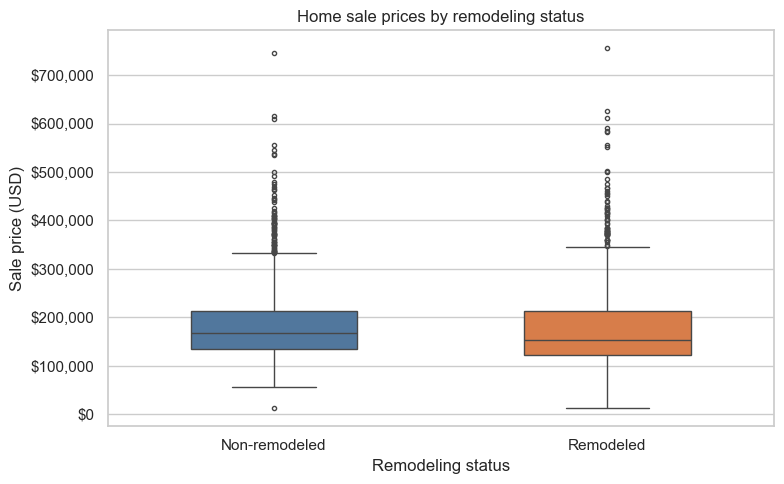

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=eda_df, x='RemodelingStatus', y='SalePrice',
    hue='RemodelingStatus', order=status_order, hue_order=status_order,
    palette=status_colors, legend=False, width=0.5, fliersize=3, ax=ax
)
ax.set_title('Home sale prices by remodeling status')
ax.set_xlabel('Remodeling status')
ax.set_ylabel('Sale price (USD)')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
fig.tight_layout()
fig.savefig('AmesHousing_SalePrice_Boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

### Average sale price by home age and remodeling status

Compare the two remodeling groups within each age category. Bars show arithmetic means, with a zero baseline and no uncertainty intervals. The counts for these six groups are available in Section 9.

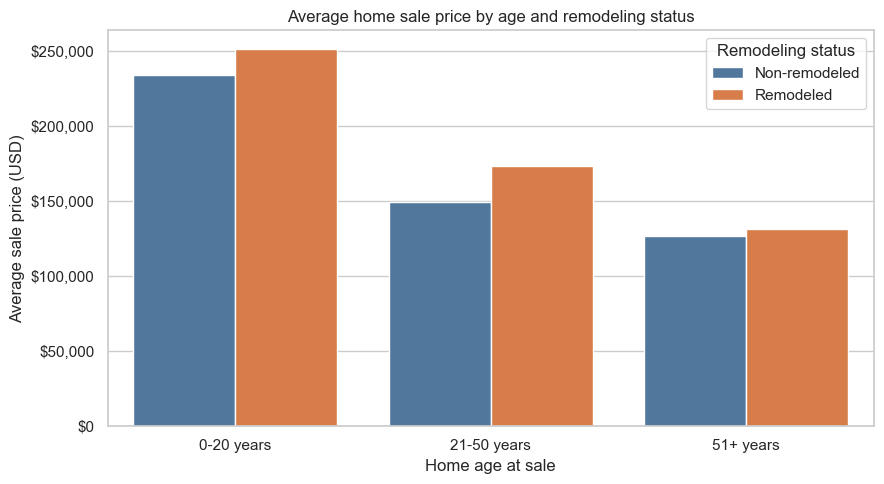

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=eda_df, x='HomeAgeGroup', y='SalePrice',
    hue='RemodelingStatus', hue_order=status_order,
    order=['0-20 years', '21-50 years', '51+ years'],
    palette=status_colors, estimator='mean', errorbar=None, ax=ax
)
ax.set_title('Average home sale price by age and remodeling status')
ax.set_xlabel('Home age at sale')
ax.set_ylabel('Average sale price (USD)')
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
ax.legend(title='Remodeling status')
fig.tight_layout()
fig.savefig('AmesHousing_AveragePrice_by_Age.png', dpi=150, bbox_inches='tight')
plt.show()

### Descriptive statistics for price, living area, and quality

`describe()` reports the count, mean, standard deviation, minimum, quartiles, and maximum. `SalePrice` is in dollars, `Gr Liv Area` is above ground living area in square feet, and `Overall Qual` is an ordered rating from 1 to 10. Quality averages summarize these ratings but do not imply equally sized differences between rating levels.

In [15]:
descriptive_statistics = analysis_df[
    ['SalePrice', 'Gr Liv Area', 'Overall Qual']
].describe().round(2)

descriptive_statistics

,SalePrice,Gr Liv Area,Overall Qual
count,2926.00,2926.00,2926.00
mean,180758.97,1497.17,6.09
std,79926.73,497.86,1.41
min,12789.00,334.00,1.00
25%,129500.00,1126.00,5.00
50%,160000.00,1441.50,6.00
75%,213500.00,1741.50,7.00
max,755000.00,5642.00,10.00


### Observed patterns

- **Overall comparison:** Non-remodeled homes have a higher average sale price ($184,312.78 versus $176,649.96) and median ($167,000 versus $153,500). Both groups have means above their medians, consistent with a longer upper price tail.
- **Within age categories:** Remodeled homes have higher average prices in all three categories. The remodeled minus non-remodeled gaps are approximately $17,164 for ages 0-20, $24,542 for ages 21-50, and $4,648 for ages 51+. Newer homes have higher average prices in both remodeling groups. These descriptive gaps vary by age; they are not tests of statistical significance.
- **Group composition matters:** 708 of 1,357 remodeled homes are in the 51+ category, compared with 176 of 1,569 non-remodeled homes. This age imbalance helps explain why the overall comparison runs in the opposite direction from the comparisons within age groups. Broad categories still contain homes of different ages.
- **Price, area, and quality vary:** Sale prices range from $12,789 to $755,000, living area from 334 to 5,642 square feet, and overall quality from 1 to 10. The middle 50% of quality ratings falls between 5 and 7. Differences in living area and quality could also be related to the observed price comparisons.

These are associations based on recorded remodeling years. The tables and plots do not control for living area or quality, establish causation, or fully answer the adjusted analytical question. The regression below addresses the specified controls and age interaction.

## 11. Multiple linear regression with a remodeling-by-age interaction

Use `SalePrice` in dollars as the dependent variable and the 2,926 cleaned observations. Rename the two column names containing spaces in a separate regression copy to keep the formula readable. `Remodeled * HomeAge` includes `Remodeled`, `HomeAge`, and their interaction. Numeric age is used here rather than the descriptive age categories.

Model: `SalePrice = intercept + b1*Remodeled + b2*HomeAge + b3*LivingArea + b4*OverallQuality + b5*Remodeled*HomeAge + error`. Overall quality is treated as a numeric rating, assuming the same price difference for each one-point increment.

In [16]:
import statsmodels.formula.api as smf

regression_df = analysis_df.rename(columns={
    'Gr Liv Area': 'LivingArea',
    'Overall Qual': 'OverallQuality'
})

model = smf.ols(
    'SalePrice ~ Remodeled * HomeAge + LivingArea + OverallQuality',
    data=regression_df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.770
Model:                            OLS   Adj. R-squared:                  0.769
Method:                 Least Squares   F-statistic:                     1953.
Date:                Sun, 18 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:37:17   Log-Likelihood:                -35034.
No. Observations:                2926   AIC:                         7.008e+04
Df Residuals:                    2920   BIC:                         7.012e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -6.194e+04   5268.05

### Model fit and relevant p-values

Print small p-values explicitly because the full summary rounds some to `0.000`; this does not mean a probability of exactly zero. The joint F-test asks whether both remodeling terms are zero, which would mean no remodeling association at any age in this model.

In [17]:
print(f'Observations: {int(model.nobs)}')
print(f'R-squared: {model.rsquared:.4f}')
print(f'Adjusted R-squared: {model.rsquared_adj:.4f}')

for term in ['Remodeled', 'HomeAge', 'Remodeled:HomeAge',
             'LivingArea', 'OverallQuality']:
    print(f'{term}: coefficient = {model.params[term]:,.2f}, '
          f'p-value = {model.pvalues[term]:.4g}')

joint_test = model.f_test('Remodeled = 0, Remodeled:HomeAge = 0')
print()
print('Joint test of the two remodeling terms:')
print(joint_test)

Observations: 2926
R-squared: 0.7698
Adjusted R-squared: 0.7694
Remodeled: coefficient = 15,035.46, p-value = 6.339e-10
HomeAge: coefficient = -418.21, p-value = 9.431e-12
Remodeled:HomeAge: coefficient = -192.08, p-value = 0.001781
LivingArea: coefficient = 65.90, p-value = 1.887e-251
OverallQuality: coefficient = 25,730.88, p-value = 2.997e-204

Joint test of the two remodeling terms:
<F test: F=22.027632110082486, p=3.198673467875353e-10, df_denom=2.92e+03, df_num=2>


### Estimated remodeling price differences at selected ages

At age `a`, the estimated remodeled minus non-remodeled price difference is `b1 + b5*a`, comparing homes of the same age, living area, and quality. Use a linear contrast to calculate a 95% confidence interval and p-value for each selected age. These are pointwise intervals for the modeled average difference, not prediction intervals for individual sales.

In [18]:
age_comparisons = []
for age in [20, 50, 80]:
    contrast = model.t_test(f'Remodeled + {age} * Remodeled:HomeAge = 0')
    interval = contrast.conf_int()[0]
    age_comparisons.append({
        'HomeAge': age,
        'Estimated_price_difference': contrast.effect.item(),
        'CI_95_lower': interval[0],
        'CI_95_upper': interval[1],
        'p_value': contrast.pvalue.item()
    })

age_comparisons = pd.DataFrame(age_comparisons)
age_comparisons.style.format({
    'HomeAge': '{:.0f}',
    'Estimated_price_difference': '${:,.2f}',
    'CI_95_lower': '${:,.2f}',
    'CI_95_upper': '${:,.2f}',
    'p_value': '{:.4g}'
})

,HomeAge,Estimated_price_difference,CI_95_lower,CI_95_upper,p_value
0,20,"$11,193.96","$7,858.99","$14,528.93",5.503e-11
1,50,"$5,431.70","$1,473.15","$9,390.25",0.007176
2,80,$-330.55,"$-7,136.52","$6,475.41",0.9241


### Sensitivity of inference to unequal residual variance

The main OLS output uses conventional standard errors, which assume constant residual variance. As a sensitivity check, HC3 standard errors allow residual variance to differ across observations. This keeps the fitted coefficients and R-squared unchanged. It does not address omitted variables or an incorrect model shape.

In [19]:
robust_model = model.get_robustcov_results(cov_type='HC3')
robust_pvalues = pd.Series(robust_model.pvalues, index=model.params.index)

print(f'HC3 remodeling p-value: {robust_pvalues["Remodeled"]:.4g}')
print(f'HC3 interaction p-value: {robust_pvalues["Remodeled:HomeAge"]:.4g}')

HC3 remodeling p-value: 1.541e-06
HC3 interaction p-value: 0.00331


### Interpretation

- **Model fit:** R-squared is **0.7698** (adjusted R-squared **0.7694**). The model accounts for about **77.0%** of the observed variation in sale price in this sample. This is not a measure of out-of-sample prediction accuracy.
- **Remodeling coefficient:** The coefficient is **+$15,035.46** (p = **6.34e-10**). With the interaction included, this is the modeled remodeling price difference specifically at **age zero**, holding living area and quality constant. No age-zero home can be classified as remodeled under our cleaned year rules, so this reference comparison is an extrapolation. It should not be described as an overall remodeling premium.
- **Interaction:** The remodeling-by-age coefficient is **-$192.08 per year** (p = **0.0018**). Each additional year of age is associated with a $192.08 reduction in the modeled remodeled minus non-remodeled price difference, holding living area and quality constant. The model therefore provides evidence that the remodeling relationship differs with age. This assumes a linear change across ages.
- **Differences at meaningful ages:** The estimated remodeling difference is approximately **+$11,194 at age 20**, **+$5,432 at age 50**, and **-$331 at age 80**. The contrast table supplies confidence intervals and p-values; a negative point estimate alone does not establish a negative association at that age.
- **Association after adjustment:** The joint test of both remodeling terms has p = **3.20e-10**, supporting an association with sale price after controlling for age, square footage, and quality. The association depends on age; this is not evidence of a positive difference at every age. The interaction remains significant with HC3 standard errors (p = **0.0033**; remodeling reference-term p = **1.54e-6**).
- **Controls:** An additional square foot of living area is associated with about **$65.90** higher sale price (p = **1.89e-251**), and a one-point increase in overall quality with about **$25,731** higher price (p = **3.00e-204**), holding the other included variables constant. The age coefficient for non-remodeled homes is **-$418.21 per year** (p = **9.43e-12**); for remodeled homes the age slope is approximately **-$610.29 per year** after adding the interaction.

These are conditional associations in observational data, not proof that remodeling causes price changes. Recorded years do not describe renovation scope, and factors such as neighborhood, sale year, and condition are not controlled here. The summary also indicates non-normal residuals; HC3 addresses unequal variance but does not establish that the linear specification is adequate. Further model diagnostics would be needed before relying on this model for prediction.

## Findings

Remodeling status was associated with sale price after accounting for home age, square footage, and overall quality, but the relationship differed with age. The results support higher estimated prices for remodeled homes at ages 20 and 50, with a smaller difference for older homes. They do not support a higher price for remodeled homes at every age.

Among the 2,926 homes, the 1,357 remodeled homes had a lower average sale price than the 1,569 non-remodeled homes ($176,649.96 versus $184,312.78). Their median price was also lower ($153,500 versus $167,000). The boxplot showed substantial overlap between the two groups and unusually high sale prices in both. However, the age-group chart showed higher average prices for remodeled homes within each of the three age categories. Remodeled homes were more concentrated in the oldest category, which helps explain why the overall comparison differed from the comparisons within age groups.

After controlling for square footage and overall quality, the regression estimated that a remodeled home sold for about $11,194 more at age 20 and $5,432 more at age 50 than a non-remodeled home of the same age, size, and quality. The estimated difference decreased by about $192 for each additional year of age. The remodeling-by-age interaction was statistically significant (p = 0.0018), supporting an age-dependent relationship. At age 80, the estimated difference was about -$331 and was not statistically distinguishable from zero (p = 0.9241). The model explained approximately 77% of the observed variation in sale prices (R-squared = 0.7698).

Overall, these findings support an association between remodeling and higher sale prices at some ages, with the association weakening as home age increases in this model. One limitation is that the regression did not account for neighborhood, which could be related to both remodeling status and sale price. These observational results do not show that remodeling causes a home to sell for more.